# BIT 4624 - Case Study #2: Analyzing Suspicious Network Traffic
**Quentin Holbert**

FinanceTech Inc. network traffic logs, January 2023.

*Before running: upload `network_traffic.xlsx` in the Files panel on the left, then do Runtime > Run all.*

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data Cleaning and Preprocessing
### 1a. Load the dataset into a pandas DataFrame

In [2]:
network_traffic = pd.read_excel("network_traffic.xlsx")
network_traffic.shape

(2000, 7)

### 1b. Quick inspection

In [3]:
network_traffic.head()

,timestamp,source_ip,destination_ip,protocol,length,flags,alert
0,2023-01-09 23:41:44,145.106.168.237,151.99.239.65,TCP,321,SYN,Phishing
1,2023-01-25 20:20:55,15.14.213.0,151.99.239.65,ICMP,632,SYN,NaN
2,2023-01-01 21:58:48,208.218.189.31,151.99.239.65,TCP,603,RST,NaN
3,2023-01-23 06:30:18,208.218.189.31,50.136.117.83,ICMP,541,SYN,NaN
4,2023-01-30 23:12:23,252.213.123.239,151.99.239.65,UDP,198,SYN-ACK,NaN


In [4]:
network_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       2000 non-null   datetime64[ns]
 1   source_ip       2000 non-null   object        
 2   destination_ip  2000 non-null   object        
 3   protocol        2000 non-null   object        
 4   length          2000 non-null   int64         
 5   flags           2000 non-null   object        
 6   alert           938 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 109.5+ KB


In [5]:
network_traffic.describe(include="all")

,timestamp,source_ip,destination_ip,protocol,length,flags,alert
count,2000,2000,2000,2000,2000.000000,2000,938
unique,NaN,636,6,3,NaN,4,4
top,NaN,208.218.189.31,151.99.239.65,UDP,NaN,SYN-ACK,Phishing
freq,NaN,194,1414,682,NaN,536,290
mean,2023-01-16 06:39:09.052000,NaN,NaN,NaN,772.020000,NaN,NaN
min,2023-01-01 00:36:35,NaN,NaN,NaN,40.000000,NaN,NaN
25%,2023-01-08 10:55:09.500000,NaN,NaN,NaN,414.500000,NaN,NaN
50%,2023-01-16 17:37:19.500000,NaN,NaN,NaN,762.000000,NaN,NaN
75%,2023-01-23 20:42:11.750000128,NaN,NaN,NaN,1156.250000,NaN,NaN
max,2023-01-30 23:14:57,NaN,NaN,NaN,1498.000000,NaN,NaN


**What I see:**
The dataset has 2,000 rows and 7 columns and covers Jan 1 to Jan 30, 2023. There are 636 different source IPs but only 6 destination IPs, so almost everything is going to a handful of machines. One of them, 151.99.239.65, is the destination on 1,414 rows (about 71%).

Protocols are split pretty evenly between UDP, TCP and ICMP, and the four flags are split evenly too. Packet length runs from 40 to 1,498 bytes with an average of about 772.

The only column with blanks is `alert` (1,062 of them). A blank there means no alert fired, not missing data, so 938 rows (about 47%) did trigger an alert. Phishing is the most common alert type.

## 2. Basic Data Cleaning
### 2a. Make sure timestamp is in datetime format

In [6]:
network_traffic["timestamp"] = pd.to_datetime(network_traffic["timestamp"], format="%Y-%m-%d %H:%M:%S")
network_traffic.dtypes

timestamp         datetime64[ns]
source_ip                 object
destination_ip            object
protocol                  object
length                     int64
flags                     object
alert                     object
dtype: object

In [7]:
# Check for missing values and duplicate rows
print(network_traffic.isna().sum())
print("\nDuplicate rows:", network_traffic.duplicated().sum())

timestamp            0
source_ip            0
destination_ip       0
protocol             0
length               0
flags                0
alert             1062
dtype: int64

Duplicate rows: 0


In [8]:
# A blank alert just means nothing was flagged, so label it "None"
# so those rows show up in counts instead of being skipped
network_traffic["alert"] = network_traffic["alert"].fillna("None")
network_traffic["alert"].value_counts()

alert
None                 1062
Phishing              290
Malware               222
Data Exfiltration     220
DDoS                  206
Name: count, dtype: int64

`timestamp` is now `datetime64`. There are no duplicate rows. The only blanks were in `alert`, and since those just mean no alert, I filled them with "None" so they get counted in the analysis below.

One thing to watch: use `network_traffic["flags"]` with brackets, not `network_traffic.flags`. `.flags` is a built-in pandas attribute, so dot notation won't return the column.

## 3. Exploratory Data Analysis (EDA)
### 3a/3b. Most active source and destination IPs using value_counts()

In [9]:
# Top 10 source IPs
network_traffic["source_ip"].value_counts().head(10)

source_ip
208.218.189.31     194
252.213.123.239    192
145.106.168.237    178
15.14.213.0        177
33.234.69.221      177
151.99.239.65       89
195.58.131.198       5
62.74.202.137        5
66.77.20.46          5
178.223.94.17        5
Name: count, dtype: int64

In [10]:
# Destination IPs (there are only 6)
network_traffic["destination_ip"].value_counts()

destination_ip
151.99.239.65      1414
169.210.202.187     136
153.18.211.92       116
50.136.117.83       115
2.212.88.236        113
77.190.226.174      106
Name: count, dtype: int64

### 3c. Same thing using groupby()

In [11]:
# Top Source IPs
top_sources = (network_traffic
               .groupby("source_ip")
               .size()
               .reset_index(name="traffic_count")
               .sort_values("traffic_count", ascending=False)
               .head(5))
top_sources

,source_ip,traffic_count
334,208.218.189.31,194
455,252.213.123.239,192
151,145.106.168.237,178
163,15.14.213.0,177
489,33.234.69.221,177


In [12]:
# Top Destination IPs
top_destinations = (network_traffic
                    .groupby("destination_ip")
                    .size()
                    .reset_index(name="traffic_count")
                    .sort_values("traffic_count", ascending=False)
                    .head(5))
top_destinations

,destination_ip,traffic_count
0,151.99.239.65,1414
2,169.210.202.187,136
1,153.18.211.92,116
4,50.136.117.83,115
3,2.212.88.236,113


#### Digging into the top IPs

In [13]:
# How much traffic comes from the top 5 vs. everyone else
counts = network_traffic["source_ip"].value_counts()
print("Rows from the top 5 source IPs:", counts.head(5).sum(), "of", len(network_traffic))
print("Source IPs that sent 5 packets or fewer:", (counts <= 5).sum())

Rows from the top 5 source IPs: 918 of 2000
Source IPs that sent 5 packets or fewer: 630


In [14]:
# Alert types for the 6 busiest source IPs
top6 = counts.head(6).index
top6_traffic = network_traffic[network_traffic["source_ip"].isin(top6)]
pd.crosstab(top6_traffic["source_ip"], top6_traffic["alert"], margins=True)

alert,DDoS,Data Exfiltration,Malware,None,Phishing,All
source_ip,,,,,,
145.106.168.237,24,22,19,88,25,178
15.14.213.0,19,17,18,100,23,177
151.99.239.65,4,6,11,52,16,89
208.218.189.31,22,24,24,95,29,194
252.213.123.239,15,23,22,107,25,192
33.234.69.221,19,19,17,93,29,177
All,103,111,111,535,147,1007


In [15]:
# Alerts sent to each destination
pd.crosstab(network_traffic["destination_ip"], network_traffic["alert"], margins=True)

alert,DDoS,Data Exfiltration,Malware,None,Phishing,All
destination_ip,,,,,,
151.99.239.65,142,163,151,755,203,1414
153.18.211.92,12,12,13,56,23,116
169.210.202.187,17,15,19,67,18,136
2.212.88.236,10,10,17,55,21,113
50.136.117.83,11,10,13,70,11,115
77.190.226.174,14,10,9,59,14,106
All,206,220,222,1062,290,2000


In [16]:
# Rows where the source and destination are the same IP
same_ip = network_traffic[network_traffic["source_ip"] == network_traffic["destination_ip"]]
print(len(same_ip), "rows where source IP = destination IP\n")
same_ip["alert"].value_counts()

69 rows where source IP = destination IP



alert
None                 42
Phishing             12
Malware               7
Data Exfiltration     5
DDoS                  3
Name: count, dtype: int64

In [17]:
# Check if any of the top source IPs are in reserved ranges
import ipaddress
for ip in top6:
    print(f"{ip:<17} reserved: {ipaddress.ip_address(ip).is_reserved}")

208.218.189.31    reserved: False
252.213.123.239   reserved: True
145.106.168.237   reserved: False
15.14.213.0       reserved: False
33.234.69.221     reserved: False
151.99.239.65     reserved: False


**Most active IPs:**

The top five source IPs are 208.218.189.31 (194), 252.213.123.239 (192), 145.106.168.237 (178), 15.14.213.0 (177) and 33.234.69.221 (177). Together they account for 918 of the 2,000 rows, about 46%. After them comes 151.99.239.65 with 89, and then 630 other IPs that each sent 5 packets or fewer.

On the destination side, 151.99.239.65 is by far the busiest with 1,414 rows (71%), and it also received 659 of the 938 alerts (about 70%). Since it's getting hit the most, I think this is FinanceTech's main server (probably something public facing like a web or mail server) and the main target.

A few things stood out:
- **Possible LAND attack:** 151.99.239.65 is listed as both the source and destination on 69 rows. A packet where the source and destination are the same IP is the signature of a LAND attack, an old DoS trick that makes a machine keep replying to itself. 42 of those 69 rows didn't trigger any alert, so the IDS is missing this.
- **Spoofed IP:** 252.213.123.239, the #2 source, is in 240.0.0.0/4, a reserved block that shouldn't show up on the internet at all. That address is most likely spoofed, and Section 4 shows it's part of a much bigger pattern.
- **Not one attacker, one attack:** Each of the top sources triggered all four alert types at about the same rate as everyone else (around 47%). Combined with the 630 IPs sending only a few packets each, this looks more like coordinated or distributed activity than one bad actor.

### 3d. Protocol usage patterns

In [18]:
protocol_counts = network_traffic["protocol"].value_counts()
print(protocol_counts)
print()
print((protocol_counts / len(network_traffic) * 100).round(1))

protocol
UDP     682
TCP     670
ICMP    648
Name: count, dtype: int64

protocol
UDP     34.1
TCP     33.5
ICMP    32.4
Name: count, dtype: float64


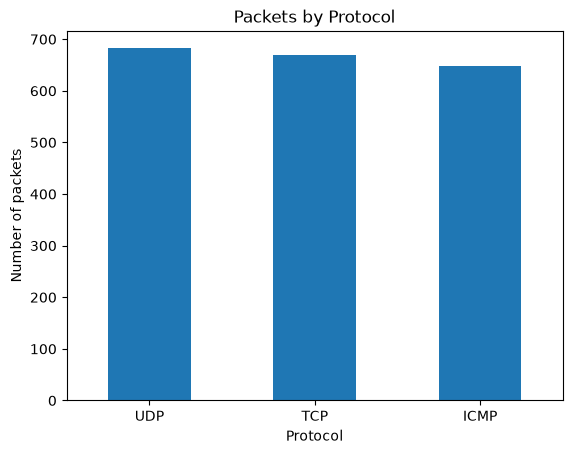

In [19]:
protocol_counts.plot(kind="bar")
plt.title("Packets by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of packets")
plt.xticks(rotation=0)
plt.show()

In [20]:
# Alert types by protocol
pd.crosstab(network_traffic["protocol"], network_traffic["alert"], margins=True)

alert,DDoS,Data Exfiltration,Malware,None,Phishing,All
protocol,,,,,,
ICMP,60,74,68,356,90,648
TCP,58,62,78,364,108,670
UDP,88,84,76,342,92,682
All,206,220,222,1062,290,2000


In [21]:
# Average packet length by protocol
network_traffic.groupby("protocol")["length"].mean().round(1)

protocol
ICMP    734.2
TCP     781.7
UDP     798.4
Name: length, dtype: float64

In [22]:
# Flags by protocol
pd.crosstab(network_traffic["protocol"], network_traffic["flags"])

flags,ACK,RST,SYN,SYN-ACK
protocol,,,,
ICMP,176,152,154,166
TCP,150,158,172,190
UDP,176,180,146,180


**Protocol usage:**

Traffic is split almost evenly: UDP 682 (34.1%), TCP 670 (33.5%) and ICMP 648 (32.4%). That isn't normal. On a typical business network TCP carries most of the traffic (web, email, file transfers) and ICMP is a small slice, mostly pings and error messages. ICMP making up a third of everything points to ping floods or network scanning.

Looking at alerts by protocol:
- **UDP** has the most DDoS alerts (88 vs. 60 for ICMP and 58 for TCP). That fits, since UDP floods are a common DDoS method because UDP doesn't need a handshake.
- **TCP** has the most Phishing (108) and Malware (78) alerts, which makes sense because email and web downloads run over TCP.
- **Data Exfiltration** is highest on UDP (84) and ICMP (74). Sending data out over UDP or ICMP (like DNS or ICMP tunneling) is a common way to sneak it past firewalls.

Average packet size is close across all three (ICMP 734, TCP 782, UDP 798 bytes). ICMP averaging 734 bytes is a red flag on its own. A normal ping is under 100 bytes, so lots of large ICMP packets could mean data hidden inside ICMP or a ping flood.

Also, SYN, ACK and RST flags show up on ICMP and UDP rows, but those are TCP-only flags. Either the logging tool is mislabeling data or these packets were crafted on purpose, which attack tools do. Either way it should be checked.

### 3e. Distribution of traffic over time
Adding a `date` column with just the month, day and year:

In [23]:
network_traffic["date"] = network_traffic["timestamp"].dt.date
network_traffic.head()

,timestamp,source_ip,destination_ip,protocol,length,flags,alert,date
0,2023-01-09 23:41:44,145.106.168.237,151.99.239.65,TCP,321,SYN,Phishing,2023-01-09
1,2023-01-25 20:20:55,15.14.213.0,151.99.239.65,ICMP,632,SYN,None,2023-01-25
2,2023-01-01 21:58:48,208.218.189.31,151.99.239.65,TCP,603,RST,None,2023-01-01
3,2023-01-23 06:30:18,208.218.189.31,50.136.117.83,ICMP,541,SYN,None,2023-01-23
4,2023-01-30 23:12:23,252.213.123.239,151.99.239.65,UDP,198,SYN-ACK,None,2023-01-30


In [24]:
# create a data frame to summarize daily volume
daily_volume = (network_traffic
                .groupby("date")
                .size()
                .reset_index(name="traffic_count"))
daily_volume.describe()

,traffic_count
count,30.000000
mean,66.666667
std,8.343213
min,48.000000
25%,60.500000
50%,67.000000
75%,73.500000
max,80.000000


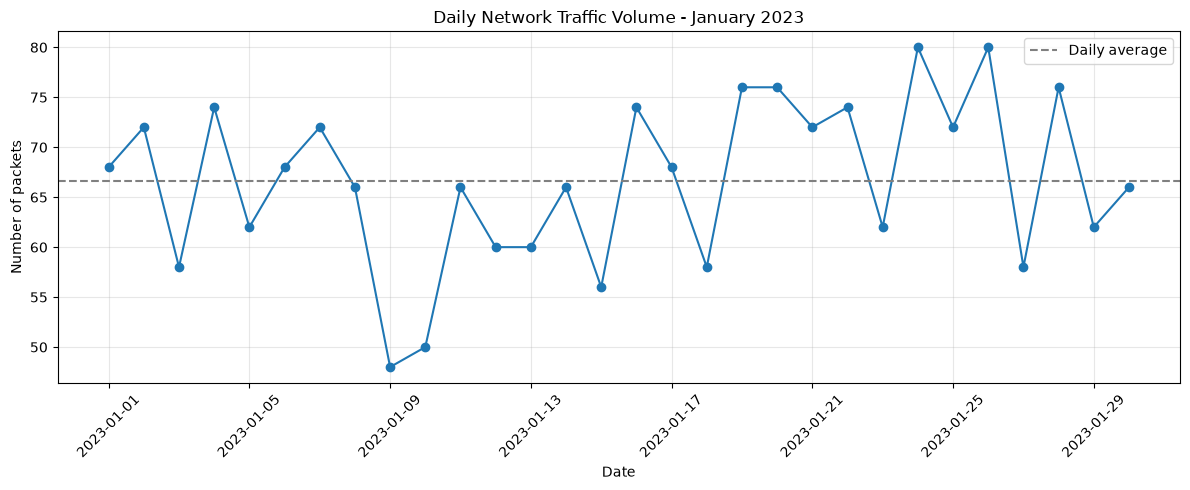

In [25]:
# plot the daily volume using matplotlib and the daily_volume data frame
plt.figure(figsize=(12, 5))
plt.plot(daily_volume["date"], daily_volume["traffic_count"], marker="o")
plt.axhline(daily_volume["traffic_count"].mean(), color="gray", linestyle="--", label="Daily average")
plt.title("Daily Network Traffic Volume - January 2023")
plt.xlabel("Date")
plt.ylabel("Number of packets")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Busiest and slowest days, and first half vs. second half of the month
print(daily_volume.sort_values("traffic_count", ascending=False).head(5))
print()
print(daily_volume.sort_values("traffic_count").head(3))
print()
print("Avg per day, Jan 1-15: ", round(daily_volume["traffic_count"].iloc[:15].mean(), 1))
print("Avg per day, Jan 16-30:", round(daily_volume["traffic_count"].iloc[15:].mean(), 1))

          date  traffic_count
23  2023-01-24             80
25  2023-01-26             80
18  2023-01-19             76
19  2023-01-20             76
27  2023-01-28             76

          date  traffic_count
8   2023-01-09             48
9   2023-01-10             50
14  2023-01-15             56

Avg per day, Jan 1-15:  63.1
Avg per day, Jan 16-30: 70.3


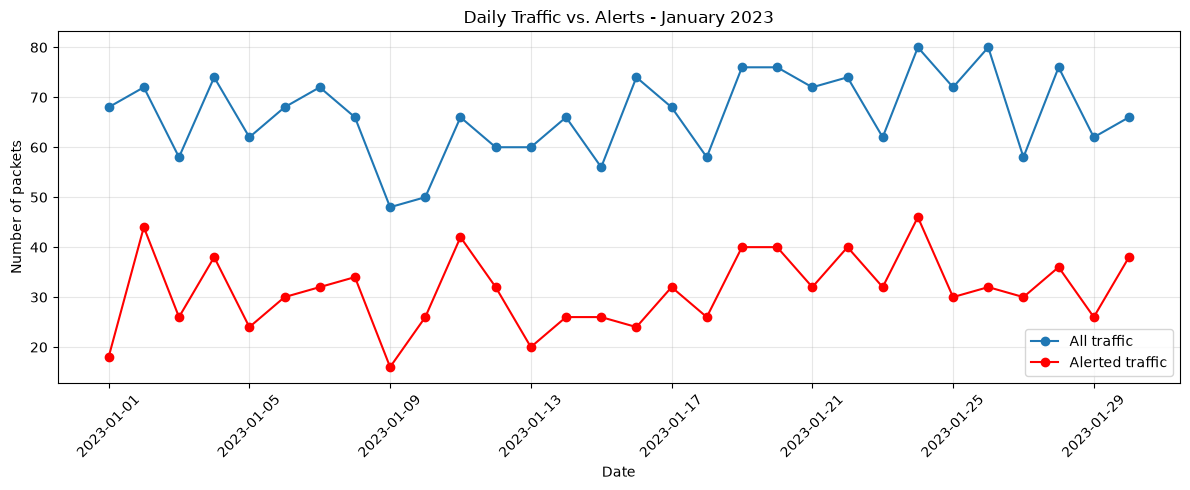

In [27]:
# Total traffic vs. traffic that triggered an alert, per day
daily_alerts = (network_traffic[network_traffic["alert"] != "None"]
                .groupby("date")
                .size()
                .reset_index(name="alert_count"))

plt.figure(figsize=(12, 5))
plt.plot(daily_volume["date"], daily_volume["traffic_count"], marker="o", label="All traffic")
plt.plot(daily_alerts["date"], daily_alerts["alert_count"], marker="o", color="red", label="Alerted traffic")
plt.title("Daily Traffic vs. Alerts - January 2023")
plt.xlabel("Date")
plt.ylabel("Number of packets")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

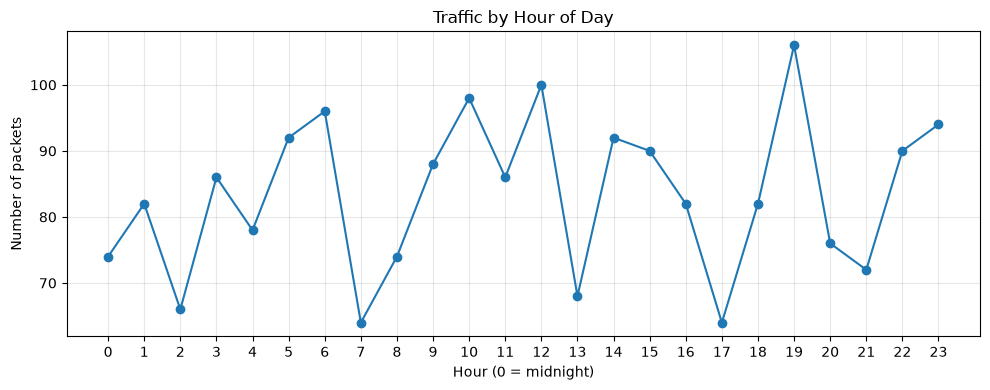

Avg per hour, midnight-6 AM: 79.7
Avg per hour, 9 AM-5 PM:    88.0


In [28]:
# Traffic by hour of day
network_traffic["hour"] = network_traffic["timestamp"].dt.hour
hourly_volume = network_traffic.groupby("hour").size()

plt.figure(figsize=(10, 4))
plt.plot(hourly_volume.index, hourly_volume.values, marker="o")
plt.title("Traffic by Hour of Day")
plt.xlabel("Hour (0 = midnight)")
plt.ylabel("Number of packets")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Avg per hour, midnight-6 AM:", round(hourly_volume.loc[0:5].mean(), 1))
print("Avg per hour, 9 AM-5 PM:   ", round(hourly_volume.loc[9:16].mean(), 1))

**Traffic over time:**

Traffic averaged about 67 packets a day, ranging from 48 on Jan 9 to 80 on Jan 24 and Jan 26. There's a dip on Jan 9-10, and then volume picks up in the second half of the month. The first 15 days averaged about 63 a day and the last 15 averaged about 70, roughly an 11% increase, and all five of the busiest days are after Jan 18. (The data stops on Jan 30, so Jan 31 isn't included.)

Alerts generally rise and fall with total traffic. There's no single huge spike, so this doesn't look like one big burst attack. It looks more like steady, ongoing malicious activity that's slowly ramping up.

The hourly chart is also pretty flat. Between midnight and 6 AM there's an average of about 80 packets an hour, compared to about 88 during the workday. For a finance company with normal office hours you'd expect a big drop overnight, so a lot of this traffic is probably automated (bots or scripts) and not employees. (This assumes the timestamps are in local time.)

## 4. Mitigation Strategies

Before proposing fixes I wanted to turn the EDA into something I could act on. The code in this section does three things:
1. Ranks the threats using the alert data.
2. Tests how much of the flagged traffic some simple firewall rules would actually stop.
3. Looks at what's left over that firewall rules can't handle.

The strategies in 4a and the rollout plan in 4b are based on those results.

### Step 1: Threat summary

In [29]:
alerts = network_traffic[network_traffic["alert"] != "None"]

threat_summary = (alerts
                  .groupby("alert")
                  .agg(alert_count=("alert", "size"),
                       pct_to_main_server=("destination_ip", lambda x: round((x == "151.99.239.65").mean() * 100, 1)),
                       top_protocol=("protocol", lambda x: x.value_counts().idxmax()),
                       pct_overnight=("hour", lambda x: round((x < 6).mean() * 100, 1)))
                  .sort_values("alert_count", ascending=False))
threat_summary["pct_of_all_alerts"] = (threat_summary["alert_count"] / len(alerts) * 100).round(1)
threat_summary

,alert_count,pct_to_main_server,top_protocol,pct_overnight,pct_of_all_alerts
alert,,,,,
Phishing,290,70.0,TCP,27.6,30.9
Malware,222,68.0,TCP,29.7,23.7
Data Exfiltration,220,74.1,UDP,20.9,23.5
DDoS,206,68.9,UDP,19.4,22.0


Phishing is the most common alert, but all four types are close (206 to 290). Every type is aimed at 151.99.239.65 about 70% of the time, so that server is the common target no matter what kind of attack it is. Between 19% and 30% of each type happens between midnight and 6 AM. Malware has the highest overnight share, which could be infected machines checking in automatically.

### Step 2: Where is the traffic really coming from?

In [30]:
# Sort every source IP into a category
def ip_type(ip):
    addr = ipaddress.ip_address(ip)
    if addr in ipaddress.ip_network("240.0.0.0/4"):
        return "Reserved (240.0.0.0/4)"
    if addr in ipaddress.ip_network("224.0.0.0/4"):
        return "Multicast (224.0.0.0/4)"
    if addr in ipaddress.ip_network("127.0.0.0/8"):
        return "Loopback (127.0.0.0/8)"
    if addr in ipaddress.ip_network("0.0.0.0/8"):
        return "This network (0.0.0.0/8)"
    if addr.is_private:
        return "Private (10.x etc.)"
    return "Public"

network_traffic["source_type"] = network_traffic["source_ip"].apply(ip_type)

(network_traffic
 .groupby("source_type")
 .agg(unique_ips=("source_ip", "nunique"),
      packets=("source_ip", "size"),
      alerts=("alert", lambda x: (x != "None").sum()))
 .sort_values("packets", ascending=False))

,unique_ips,packets,alerts
source_type,,,
Public,549,1678,792
Reserved (240.0.0.0/4),40,248,108
Multicast (224.0.0.0/4),36,55,27
This network (0.0.0.0/8),6,10,5
Loopback (127.0.0.0/8),3,6,3
Private (10.x etc.),2,3,3


This was the biggest surprise. **85 of the 636 source IPs can't legitimately send traffic across the internet**, and they account for 319 packets and 143 alerts:
- 40 are in 240.0.0.0/4, a reserved block that isn't used on the internet.
- 36 are multicast addresses (224.0.0.0/4). Multicast is only valid as a destination, never a source.
- 3 are loopback (127.x), which never leaves the machine it's on.
- 6 are in 0.0.0.0/8, which isn't a valid source address either.

These are spoofed. That changes the mitigation plan in two ways. First, blocking attackers by IP address won't fully work, because a lot of these aren't the attacker's real address. Second, these "bogon" addresses are normally dropped at the edge router. If these logs were captured inside the firewall, that filtering isn't turned on. The 2 private (10.x) sources could be FinanceTech's own internal machines, so I left them out of the block rule below.

### Step 3: Testing candidate firewall rules
These are four rules that a network team could put in quickly with the firewall they already have:
- **Block the top 5 source IPs.** These are the five busiest senders from Section 3.
- **Drop bogon source IPs.** These are the 85 addresses from Step 2.
- **Drop packets where source = destination.** This stops the LAND-style packets.
- **Drop ICMP packets over 128 bytes.** Normal pings from Windows and Linux are under 100 bytes, so 128 leaves room for legit traffic.

In [31]:
is_alert = network_traffic["alert"] != "None"
bogon_types = ["Reserved (240.0.0.0/4)", "Multicast (224.0.0.0/4)",
               "Loopback (127.0.0.0/8)", "This network (0.0.0.0/8)"]

rules = {
    "Block top 5 source IPs": network_traffic["source_ip"].isin(top_sources["source_ip"]),
    "Drop bogon source IPs": network_traffic["source_type"].isin(bogon_types),
    "Drop source = destination": network_traffic["source_ip"] == network_traffic["destination_ip"],
    "Drop ICMP over 128 bytes": (network_traffic["protocol"] == "ICMP") & (network_traffic["length"] > 128),
}
# a packet is blocked if any of the four rules catches it
rules["All four combined"] = pd.concat(rules.values(), axis=1).any(axis=1)

rule_results = pd.DataFrame([
    {"rule": name,
     "packets_blocked": mask.sum(),
     "alerts_blocked": (mask & is_alert).sum(),
     "pct_of_all_alerts": round((mask & is_alert).sum() / is_alert.sum() * 100, 1),
     "unalerted_packets_blocked": (mask & ~is_alert).sum()}
    for name, mask in rules.items()
])
rule_results

,rule,packets_blocked,alerts_blocked,pct_of_all_alerts,unalerted_packets_blocked
0,Block top 5 source IPs,918,435,46.4,483
1,Drop bogon source IPs,319,143,15.2,176
2,Drop source = destination,69,27,2.9,42
3,Drop ICMP over 128 bytes,614,274,29.2,340
4,All four combined,1382,638,68.0,744


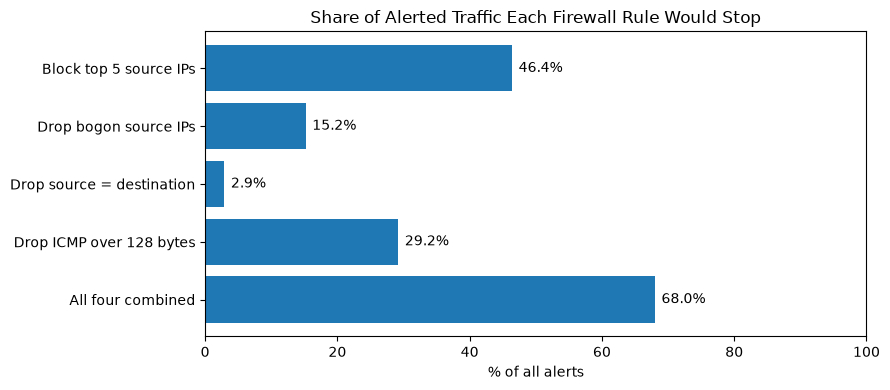

In [32]:
plt.figure(figsize=(9, 4))
plt.barh(rule_results["rule"], rule_results["pct_of_all_alerts"])
for i, pct in enumerate(rule_results["pct_of_all_alerts"]):
    plt.text(pct + 1, i, f"{pct}%", va="center")
plt.gca().invert_yaxis()
plt.title("Share of Alerted Traffic Each Firewall Rule Would Stop")
plt.xlabel("% of all alerts")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Step 4: What the firewall rules can't catch

In [33]:
remaining = network_traffic[is_alert & ~rules["All four combined"]]
print(len(remaining), "alerts get past all four rules")
print("They come from", remaining["source_ip"].nunique(), "different source IPs\n")
print(remaining["alert"].value_counts(), "\n")
print(remaining["protocol"].value_counts())

300 alerts get past all four rules
They come from 248 different source IPs

alert
Phishing             92
Malware              73
DDoS                 69
Data Exfiltration    66
Name: count, dtype: int64 

protocol
UDP     147
TCP     145
ICMP      8
Name: count, dtype: int64


**What the rule test tells me:**
- **Simple network rules handle about two thirds of the problem.** Together the four rules would stop 638 of the 938 alerted packets (68%). They're also fast and cheap, since they're just configuration on equipment FinanceTech already has.
- **The biggest single rule is also the weakest one long term.** Blocking the top 5 IPs stops 46% of alerts, but attackers can switch IPs whenever they want, and at least one of the five is spoofed. That makes it a short-term fix while the real controls get set up.
- **The ICMP size limit punches above its weight.** It catches 274 of the 292 ICMP alerts. Almost none of the ICMP here looks like normal pings.
- **Bogon filtering is a no-brainer.** It catches 15% of alerts and should already be standard practice, so there's really no reason not to do it.
- **There's a cost.** The rules would also drop 744 packets that never triggered an alert. Most of them come from the same suspicious sources, but some could be real customers or partners, which is why I'd test rules before enforcing them (see 4b).
- **The last 300 alerts need different tools.** They come from 248 IPs that mostly sent one packet each, over normal TCP and UDP. You can't firewall your way out of that. Phishing emails, malware downloads and data leaving the network have to be caught by email security, endpoint protection and data loss prevention. This is basically the case for defense in depth: no single layer covers everything.

### 4a. Proposed strategies for the top threats

I ranked the threats by likelihood (how often they show up in the data) and impact (how bad it would be for a financial company if the attack worked). Risk order isn't the same as rollout order, though. The network fixes for DDoS go in first because they're the fastest, even though phishing and data theft are the bigger long-term risks.

| Risk rank | Threat | Alerts | Likelihood | Impact for FinanceTech | Main controls |
|---|---|---|---|---|---|
| 1 | Phishing | 290 | High (most common) | High: usually the entry point for malware and data theft | Email security, MFA, training |
| 2 | Data exfiltration | 220 | High | Very high: stolen customer financial data means breach notifications, fines and lost trust | Egress filtering, DLP, encryption |
| 3 | Malware | 222 | High | High: ransomware could shut down operations | EDR, patching, segmentation, backups |
| 4 | DDoS / spoofed traffic | 206 + 319 bogon packets | High | Medium-high: customers can't reach services, but no data is lost | Edge filtering, rate limits, upstream DDoS protection |

#### 1. Phishing (290 alerts)
**What the data shows:** It's the most common alert, it's mostly on TCP (where email and web traffic run), and 28% of it happens overnight, which suggests automated campaigns.

**Why it's ranked first:** Phishing is how attackers usually get in. A stolen password or a malicious attachment then leads to the malware and data theft alerts. So fixing phishing also cuts down the other threats.

**Strategies:**
- **Secure email gateway.** Scan links and attachments, open suspicious attachments in a sandbox first, and tag emails from outside the company with an [EXTERNAL] banner.
- **SPF, DKIM and DMARC.** These stop attackers from sending email that looks like it came from FinanceTech's domain, which protects both employees and customers. DMARC should eventually be set to reject.
- **MFA for everyone.** Then a stolen password alone isn't enough to log in. Admins and finance staff should get phishing-resistant MFA like security keys or passkeys, since push notifications and text codes can still be phished.
- **Training and simulated phishing.** Monthly fake phishing emails, short training for anyone who clicks, and a "Report Phish" button in Outlook. The goal is a lower click rate and a higher report rate over time.
- **DNS filtering.** Block known phishing domains, so even if someone clicks, the page doesn't load.

#### 2. Data exfiltration (220 alerts)
**What the data shows:** It's highest on UDP (38%) and ICMP (34%), the two protocols most often abused to tunnel data out (DNS tunneling and ICMP tunneling). The large average ICMP packet size fits that too. 74% of these alerts involve 151.99.239.65, so that server either holds data attackers want or is being used as a staging point.

**Why it matters so much:** For a finance company this is probably the most damaging outcome. Customer account data leaking means breach notifications, regulators getting involved, possible fines and lawsuits, and customers losing trust.

**Strategies:**
- **Egress filtering (default deny outbound).** Servers should only be able to connect out to what they actually need. The main server has no reason to start connections to random internet hosts.
- **Lock down DNS.** Force all DNS through FinanceTech's internal DNS servers, block outbound port 53 from everything else, and alert on unusually long or frequent DNS queries, which are a sign of tunneling.
- **Restrict outbound ICMP.** Block or inspect outbound ICMP packets that carry large payloads.
- **Data loss prevention (DLP).** Put it on email, the web proxy and endpoints to catch things like account numbers and SSNs leaving the network.
- **Encrypt sensitive data at rest and limit access to it.** Then even if a file gets out it's much less useful. GLBA also requires encrypting customer information.
- **Baseline outbound traffic.** Alert when a host sends much more data than normal, especially overnight.

#### 3. Malware (222 alerts)
**What the data shows:** It's spread across all three protocols, slightly highest on TCP, and has the highest overnight share (30%). That fits infected machines running on their own.

**Strategies:**
- **Endpoint detection and response (EDR) on every workstation and server.** It needs someone watching it 24/7, either an in-house SOC or an outside managed detection and response (MDR) provider.
- **Patch management.** Critical patches within a few days, everything else monthly, plus regular vulnerability scans to find what was missed.
- **Least privilege.** Users shouldn't be local admins, and servers should only run approved applications (allowlisting).
- **Network segmentation.** An infected laptop shouldn't be able to reach the main server or the databases directly.
- **Offline or immutable backups that are actually tested.** Backups are what make ransomware recoverable without paying.
- **Threat intelligence feeds.** Use them to block known command-and-control servers.

#### 4. DDoS and spoofed traffic (206 DDoS alerts, 85 spoofed source IPs, 69 LAND packets)
**What the data shows:** UDP carries 43% of the DDoS alerts. ICMP is a third of all traffic and nearly all of it is oversized. 85 source IPs are spoofed, and 42 of the 69 source = destination packets didn't trigger any alert.

**Strategies:**
- **Bogon / ingress filtering at the edge router.** Drop inbound packets with reserved, multicast, loopback or 0.x source addresses, and also any packet from outside that claims to come from FinanceTech's own address range. FinanceTech should also filter its outbound traffic so its own network can't be used to send spoofed packets. That's the idea behind BCP 38 (RFC 2827).
- **Drop source = destination packets and add an IDS rule for them.** Snort and Suricata both support this with the `sameip` rule option. Right now most of these packets get through without an alert.
- **Limit ICMP.** Rate limit and size limit ping (echo) requests, but still allow the ICMP messages the network needs, like "destination unreachable / fragmentation needed". Blocking all ICMP breaks Path MTU Discovery and causes weird connection problems. My test above used a simple size rule because the data doesn't include ICMP types. A real rule would be more specific.
- **Rate limiting and SYN cookies.** Rate limit connections per source IP, and turn on SYN cookies on the servers to handle SYN floods.
- **Upstream DDoS protection.** Use the ISP's scrubbing service or a provider like Cloudflare or AWS Shield. A big enough flood fills up the internet connection before it ever reaches FinanceTech's firewall, so on-site rules alone can't stop it.
- **Hide the main server behind a CDN, load balancer or WAF.** Keep its real IP address private.

### 4b. Implementing these in a real-world scenario

#### Rollout plan
I'd roll this out in phases. The quick network fixes buy time while the bigger controls get set up.

| Phase | Timeline | Actions | Owner | How we know it worked |
|---|---|---|---|---|
| 1. Contain | Day 1-2 | Bogon filtering, drop source = destination, ICMP limits, temporary block or rate limit on the top 5 IPs. Check 151.99.239.65 for compromise and save the logs as evidence. | Network team, security analyst | Bogon and source = destination packets reaching the network drop to 0. ICMP falls from 32% of traffic to under 5%. |
| 2. Harden | Weeks 1-6 | SPF/DKIM/DMARC, MFA rollout, email gateway rules, EDR (servers first, then workstations), egress filtering, DNS lockdown, sign a DDoS protection contract | IT, security, email admin | MFA coverage near 100%. EDR on every server. Daily alert volume trending down. |
| 3. Monitor | Months 2-3 | Send logs to a SIEM (like Splunk or Microsoft Sentinel) with alert rules for the patterns found here, deploy DLP, fix the logging issue, write and test the incident response plan | Security team / MDR provider | Alerts fire for the patterns found here. The first tabletop exercise is done. |
| 4. Sustain | Ongoing | Monthly patching, monthly phishing tests, vulnerability scans, yearly pen test, quarterly firewall rule review, re-run this analysis on each month's logs | Everyone, with security leading | Phishing click rate going down. Metrics below improving month over month. |

#### Test before enforcing
Every new firewall or IDS rule should run in log-only mode for a week or two before it starts blocking. My rule test shows why. The four rules would also have dropped 744 packets that never triggered an alert. Most of those come from the same suspicious sources, but some could be real customers or partners. For a finance company, accidentally blocking customers from logging in is its own kind of outage. After reviewing what would have been blocked, the team switches the rule to enforce. Every change should go through change management with a written rollback plan.

#### Limits and trade-offs
- **IP blocking is a band-aid.** Attackers rotate IPs, and spoofed addresses aren't the real source anyway. It buys time but doesn't solve anything.
- **On-site filtering can't stop a flood big enough to fill the internet connection.** That's why upstream DDoS protection is in Phase 2.
- **Encryption hides traffic from DLP and IDS tools.** Most traffic is HTTPS now, so these tools can't see inside it unless the company does TLS inspection. That costs money, slows things down, and raises privacy questions, especially for employees' personal banking or health sites.
- **Security adds friction.** MFA and stricter email filtering annoy people at first. The rollout needs clear communication and help desk support, or people find workarounds.
- **Cost and staffing.** EDR, a SIEM, DDoS protection and 24/7 monitoring all cost money. For a mid-size company, paying a managed security provider is often cheaper than building a 24/7 security team in-house. Management needs to approve the budget, and framing it as risk and compliance (below) helps get that approval.
- **The data has to be trustworthy.** The IDS missed 42 of the 69 source = destination packets, and the logs show TCP flags on UDP and ICMP traffic. Fixing the logging and tuning the IDS comes before trusting any metric built on it.

#### Compliance
As a financial company, FinanceTech likely falls under the FTC's GLBA Safeguards Rule. The 2021 update (in effect since June 2023) requires many of the controls above, including MFA, encryption of customer information, a written incident response plan, and either continuous monitoring or yearly penetration testing with vulnerability scans every six months. Since May 2024, a breach involving the information of at least 500 consumers also has to be reported to the FTC within 30 days of discovery. If FinanceTech handles card payments, PCI DSS applies as well. So a lot of this plan isn't optional, and that makes it easier to get budget approved.

#### Incident response
The incident response plan should spell out who does what when something like this happens: who can approve blocking traffic, who talks to customers and regulators, how evidence gets preserved, and how the team reviews what went wrong afterward. The team should practice it with tabletop exercises at least once a year. This case would be a good scenario to start with.

#### Measuring success
The same analysis in this notebook can be re-run on each month's logs and compared to January's baseline:

In [34]:
# January baseline vs. targets after the fixes are in place
kpis = pd.DataFrame({
    "baseline_jan_2023": pd.Series([
        round(daily_alerts["alert_count"].mean(), 1),
        round(is_alert.mean() * 100, 1),
        round((alerts["destination_ip"] == "151.99.239.65").mean() * 100, 1),
        round((network_traffic["protocol"] == "ICMP").mean() * 100, 1),
        int(rules["Drop bogon source IPs"].sum()),
        int(rules["Drop source = destination"].sum()),
    ], dtype="object").values,
    "target": ["Down month over month", "Down month over month", "Down once behind DDoS protection/WAF",
               "Under 5%", "0", "0"],
}, index=["Avg alerts per day", "% of traffic triggering an alert", "% of alerts aimed at 151.99.239.65",
          "ICMP share of traffic (%)", "Packets from bogon source IPs", "Source = destination packets"])
kpis

,baseline_jan_2023,target
Avg alerts per day,31.3,Down month over month
% of traffic triggering an alert,46.9,Down month over month
% of alerts aimed at 151.99.239.65,70.3,Down once behind DDoS protection/WAF
ICMP share of traffic (%),32.4,Under 5%
Packets from bogon source IPs,319,0
Source = destination packets,69,0


Outside the logs I'd also track phishing simulation click and report rates, MFA coverage, patch compliance, EDR coverage, and how long it takes to detect and respond to an incident.

### Conclusion
FinanceTech's traffic shows a steady, growing campaign aimed mostly at one server (151.99.239.65), mixing all four attack types and using a lot of spoofed addresses. About two thirds of the flagged traffic can be stopped quickly with basic firewall rules (bogon filtering, dropping source = destination packets, limiting ICMP, and temporarily blocking the top IPs). The rest comes from hundreds of one-off addresses over normal protocols and needs layered controls: email security and MFA for phishing, EDR and patching for malware, and egress filtering and DLP for data theft. Rolling it out in phases, testing rules before enforcing them, and tracking the metrics above month to month makes the plan realistic for a real company. It also lines up with what GLBA already requires.

### References
- Ferguson, P., & Senie, D. (2000). *RFC 2827 / BCP 38: Network Ingress Filtering: Defeating Denial of Service Attacks which employ IP Source Address Spoofing.* https://www.rfc-editor.org/rfc/rfc2827
- Bradley Arant Boult Cummings. (2021). *FTC Finalizes Updated Safeguards Rule Under GLBA to Dramatically Expand Data Security Requirements and Scope of Rule.* https://www.bradley.com/insights/publications/2021/11/ftc-finalizes-updated-safeguards-rule-under-glba-to-dramatically-expand-data-security-requirements-and-scope-of-rule
- Federal Trade Commission. *Standards for Safeguarding Customer Information (Safeguards Rule), 16 CFR Part 314.*